# E-commerce Sales Analysis with SQL (Olist, Brazil)
**Questions:** How is revenue growing? Which products and sellers matter most? Do customers come back? How good is delivery, and does it affect reviews?
**Data:** Olist Brazilian E-commerce, 8 linked tables (about 99,000 orders, 2016-2018).
**Method:** Cleaning (pandas) -> 15 SQL queries in SQLite (joins, CTEs, window functions) -> charts -> dashboard files.

**Definitions used throughout**
- Revenue = item price (excluding freight) of orders with status `delivered`.
- Full months for growth = 2017-01 to 2018-08 (the months before and after are almost empty).
- Late delivery = delivered on a later calendar day than the estimated delivery date.
- Real customer = `customer_unique_id` (the `customer_id` column changes with every order).

## 1. Inspect the raw files

In [1]:
import glob, os
import numpy as np, pandas as pd
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
hits = [f for p in ["/kaggle/input/**/olist_orders_dataset.csv", "/home/claude/olist_raw/olist_orders_dataset.csv",
                    "./raw/olist_orders_dataset.csv", "./olist_orders_dataset.csv"]
        for f in glob.glob(p, recursive=True)]
raw_dir = os.path.dirname(hits[0])
rows = []
for f in sorted(glob.glob(raw_dir + "/*.csv")):
    t = pd.read_csv(f)
    rows.append((os.path.basename(f), t.shape[0], t.shape[1], int(t.isnull().sum().sum()), int(t.duplicated().sum())))
pd.DataFrame(rows, columns=["file", "rows", "columns", "missing_cells", "duplicate_rows"])

,file,rows,columns,missing_cells,duplicate_rows
0,olist_customers_dataset.csv,99441,5,0,0
1,olist_order_items_dataset.csv,112650,7,0,0
2,olist_order_payments_dataset.csv,103886,5,0,0
3,olist_order_reviews_dataset.csv,99224,7,145903,0
4,olist_orders_dataset.csv,99441,8,4908,0
5,olist_products_dataset.csv,32951,9,2448,0
6,olist_sellers_dataset.csv,3095,4,0,0
7,product_category_name_translation.csv,71,2,0,0


In [2]:
orders_raw = pd.read_csv(raw_dir + "/olist_orders_dataset.csv")
print(orders_raw["order_status"].value_counts(), "\n")
print("Orders per month (note the near-empty months at both ends):")
print(orders_raw["order_purchase_timestamp"].str[:7].value_counts().sort_index().to_string())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64 

Orders per month (note the near-empty months at both ends):
order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4


## 2. Clean the data
This cell is the file `01_clean_olist.py`. Every change is printed. Main fixes: one review per order, English category names (2 were missing), missing categories labelled `unknown`, dates converted.

In [3]:
"""
01_clean_olist.py
Cleans the 8 Olist tables and writes them to ./clean/ (one CSV per table).
Every change is printed so it can be copied into the README.

Revenue definition used everywhere in this project:
    revenue = item price (excluding freight) of orders whose status is "delivered".
Full months used for growth analysis: 2017-01 to 2018-08 (see log below for why).
"""
import glob, os
import numpy as np
import pandas as pd

# ---------------------------------------------------------------- locate the raw files
def find_raw_dir():
    patterns = ["/kaggle/input/**/olist_orders_dataset.csv",
                "/home/claude/olist_raw/olist_orders_dataset.csv",
                "./raw/olist_orders_dataset.csv",
                "./olist_orders_dataset.csv"]
    for p in patterns:
        hits = glob.glob(p, recursive=True)
        if hits:
            return os.path.dirname(hits[0])
    raise FileNotFoundError("olist_orders_dataset.csv not found - set RAW_DIR manually.")

RAW_DIR = find_raw_dir()
OUT_DIR = "clean"
os.makedirs(OUT_DIR, exist_ok=True)
log = []

def read(name, **kw):
    return pd.read_csv(os.path.join(RAW_DIR, name), **kw)

# ---------------------------------------------------------------- load
orders = read("olist_orders_dataset.csv",
              parse_dates=["order_purchase_timestamp", "order_approved_at",
                           "order_delivered_carrier_date", "order_delivered_customer_date",
                           "order_estimated_delivery_date"])
items = read("olist_order_items_dataset.csv", parse_dates=["shipping_limit_date"])
payments = read("olist_order_payments_dataset.csv")
reviews = read("olist_order_reviews_dataset.csv",
               parse_dates=["review_creation_date", "review_answer_timestamp"])
customers = read("olist_customers_dataset.csv")
products = read("olist_products_dataset.csv")
sellers = read("olist_sellers_dataset.csv")
translation = read("product_category_name_translation.csv")

raw_rows = {"orders": len(orders), "order_items": len(items), "payments": len(payments),
            "reviews": len(reviews), "customers": len(customers), "products": len(products),
            "sellers": len(sellers), "translation": len(translation)}
log.append("Loaded 8 tables: " + ", ".join(f"{k} {v:,}" for k, v in raw_rows.items()))

# ---------------------------------------------------------------- 1. dates
log.append("Dates: converted 5 order timestamps, shipping_limit_date and 2 review dates from text to datetime")

# ---------------------------------------------------------------- 2. orders
orders["purchase_month"] = orders["order_purchase_timestamp"].dt.strftime("%Y-%m")
orders["is_delivered"] = (orders["order_status"] == "delivered").astype(int)
n_deliv_no_date = int(((orders["is_delivered"] == 1) & orders["order_delivered_customer_date"].isna()).sum())
n_nondeliv_with_date = int(((orders["is_delivered"] == 0) & orders["order_delivered_customer_date"].notna()).sum())
n_deliv_no_approval = int(((orders["is_delivered"] == 1) & orders["order_approved_at"].isna()).sum())
log.append(f"Orders: added purchase_month and is_delivered. Left as-is on purpose: "
           f"{n_deliv_no_date} delivered orders with no delivery date (excluded from delivery metrics), "
           f"{n_nondeliv_with_date} non-delivered orders that have a delivery date (ignored because status is not delivered), "
           f"{n_deliv_no_approval} delivered orders with no approval time")

# ---------------------------------------------------------------- 3. reviews: one row per order
n_reviews_raw = len(reviews)
n_dup_review_ids = int(reviews["review_id"].duplicated().sum())
n_orders_multi = int((reviews.groupby("order_id").size() > 1).sum())
reviews = (reviews.sort_values(["order_id", "review_answer_timestamp", "review_creation_date"])
                  .drop_duplicates("order_id", keep="last"))      # keep the latest review per order
reviews["has_comment"] = reviews["review_comment_message"].notna().astype(int)
reviews = reviews[["review_id", "order_id", "review_score", "review_creation_date",
                   "review_answer_timestamp", "has_comment"]]
log.append(f"Reviews: {n_reviews_raw:,} rows -> {len(reviews):,} (one per order, latest review kept). "
           f"Reason: {n_orders_multi} orders had more than one review and {n_dup_review_ids} review_ids repeated, "
           f"which would double-count orders in joins. Comment text columns dropped (mostly empty); has_comment flag added")

# ---------------------------------------------------------------- 4. products
products = products.rename(columns={"product_name_lenght": "product_name_length",
                                    "product_description_lenght": "product_description_length"})
n_null_cat = int(products["product_category_name"].isna().sum())
products["product_category_name"] = products["product_category_name"].fillna("unknown")
log.append(f"Products: fixed 2 misspelled column names (lenght -> length); {n_null_cat} missing category names set to 'unknown'")

# ---------------------------------------------------------------- 5. translation table
missing_cats = sorted(set(products["product_category_name"]) - set(translation["product_category_name"]) - {"unknown"})
manual = {"pc_gamer": "pc_gaming",
          "portateis_cozinha_e_preparadores_de_alimentos": "portable_kitchen_and_food_preparers"}
add = pd.DataFrame([{"product_category_name": k, "product_category_name_english": v}
                    for k, v in manual.items() if k in missing_cats])
translation = pd.concat([translation, add,
                         pd.DataFrame([{"product_category_name": "unknown",
                                        "product_category_name_english": "unknown"}])],
                        ignore_index=True)
log.append(f"Translation: added English names for the {len(add)} categories missing from the file "
           f"({', '.join(missing_cats)}) and a row for 'unknown'")

# ---------------------------------------------------------------- 6. things deliberately left unchanged
log.append("Unchanged on purpose: order_items, payments, customers, sellers (no errors found). "
           "customer_unique_id is the real customer; customer_id changes with every order")

# ---------------------------------------------------------------- 7. integrity checks
assert orders["order_id"].is_unique and reviews["order_id"].is_unique
assert items["order_id"].isin(orders["order_id"]).all()
assert items["product_id"].isin(products["product_id"]).all()
assert items["seller_id"].isin(sellers["seller_id"]).all()
assert orders["customer_id"].isin(customers["customer_id"]).all()
assert products["product_category_name"].isin(translation["product_category_name"]).all()
assert len(orders) == raw_rows["orders"] and len(items) == raw_rows["order_items"]

# ---------------------------------------------------------------- 8. write
tables = {"orders": orders, "order_items": items, "payments": payments, "reviews": reviews,
          "customers": customers, "products": products, "sellers": sellers,
          "translation": translation}
for name, t in tables.items():
    t.to_csv(os.path.join(OUT_DIR, f"{name}.csv"), index=False)

d_items = items.merge(orders.loc[orders["is_delivered"] == 1, ["order_id"]], on="order_id")
log.append(f"Revenue check: delivered orders {orders['is_delivered'].sum():,}, "
           f"revenue ${d_items['price'].sum():,.2f} (price only), freight ${d_items['freight_value'].sum():,.2f}")
months = orders["purchase_month"].value_counts().sort_index()
log.append("Partial months (not used for growth): " +
           ", ".join(f"{m} ({n} orders)" for m, n in months.items() if m < "2017-01" or m > "2018-08") +
           "; 2016-11 has no orders at all")
print("\n".join(log))


Loaded 8 tables: orders 99,441, order_items 112,650, payments 103,886, reviews 99,224, customers 99,441, products 32,951, sellers 3,095, translation 71
Dates: converted 5 order timestamps, shipping_limit_date and 2 review dates from text to datetime
Orders: added purchase_month and is_delivered. Left as-is on purpose: 8 delivered orders with no delivery date (excluded from delivery metrics), 6 non-delivered orders that have a delivery date (ignored because status is not delivered), 14 delivered orders with no approval time
Reviews: 99,224 rows -> 98,673 (one per order, latest review kept). Reason: 547 orders had more than one review and 814 review_ids repeated, which would double-count orders in joins. Comment text columns dropped (mostly empty); has_comment flag added
Products: fixed 2 misspelled column names (lenght -> length); 610 missing category names set to 'unknown'
Translation: added English names for the 2 categories missing from the file (pc_gamer, portateis_cozinha_e_prepara

## 3. SQL analysis (SQLite inside the notebook)
The 15 queries below are the file `02_queries.sql`.

In [4]:
import sqlite3
conn = sqlite3.connect(":memory:")
for t in ["orders", "order_items", "payments", "reviews", "customers", "products", "sellers", "translation"]:
    pd.read_csv(f"clean/{t}.csv").to_sql(t, conn, index=False, if_exists="replace")
def q(sql): return pd.read_sql(sql, conn)

**Q1: Business overview (joins across orders, items and customers)**

In [5]:
q("""
SELECT COUNT(DISTINCT o.order_id)                                        AS orders,
       COUNT(DISTINCT CASE WHEN o.is_delivered = 1 THEN o.order_id END)  AS delivered_orders,
       COUNT(DISTINCT c.customer_unique_id)                              AS unique_customers,
       (SELECT COUNT(*) FROM sellers)                                    AS sellers,
       ROUND(SUM(CASE WHEN o.is_delivered = 1 THEN i.price END), 0)      AS revenue,
       ROUND(SUM(CASE WHEN o.is_delivered = 1 THEN i.freight_value END), 0) AS freight,
       ROUND(SUM(CASE WHEN o.is_delivered = 1 THEN i.price END)
             / COUNT(DISTINCT CASE WHEN o.is_delivered = 1 THEN o.order_id END), 2) AS avg_order_value
FROM orders o
JOIN customers c        ON c.customer_id = o.customer_id
LEFT JOIN order_items i ON i.order_id = o.order_id;
""")

,orders,delivered_orders,unique_customers,sellers,revenue,freight,avg_order_value
0,99441,96478,96096,3095,13221498.0,2198276.0,137.04


**Q2: Monthly revenue and month-over-month growth (CTE + LAG window function)**

In [6]:
q("""
WITH monthly AS (
  SELECT o.purchase_month               AS month,
         COUNT(DISTINCT o.order_id)     AS orders,
         SUM(i.price)                   AS revenue
  FROM orders o
  JOIN order_items i ON i.order_id = o.order_id
  WHERE o.is_delivered = 1
    AND o.purchase_month BETWEEN '2017-01' AND '2018-08'
  GROUP BY o.purchase_month
)
SELECT month, orders, ROUND(revenue, 0) AS revenue,
       ROUND(LAG(revenue) OVER (ORDER BY month), 0) AS prev_month_revenue,
       ROUND(100.0 * (revenue - LAG(revenue) OVER (ORDER BY month))
             / LAG(revenue) OVER (ORDER BY month), 1) AS mom_growth_pct,
       ROUND(revenue / orders, 2) AS avg_order_value
FROM monthly
ORDER BY month;
""")

,month,orders,revenue,prev_month_revenue,mom_growth_pct,avg_order_value
0,2017-01,750,111798.0,NaN,NaN,149.06
1,2017-02,1653,234223.0,111798.0,109.5,141.70
2,2017-03,2546,359199.0,234223.0,53.4,141.08
3,2017-04,2303,340670.0,359199.0,-5.2,147.92
4,2017-05,3546,489338.0,340670.0,43.6,138.00
5,2017-06,3135,421923.0,489338.0,-13.8,134.58
6,2017-07,3872,481605.0,421923.0,14.1,124.38
7,2017-08,4193,554700.0,481605.0,15.2,132.29
8,2017-09,4150,607400.0,554700.0,9.5,146.36
9,2017-10,4478,648248.0,607400.0,6.7,144.76


**Q3: Same-period year-over-year growth (January to August 2017 vs 2018)**

In [7]:
q("""
WITH ytd AS (
  SELECT SUBSTR(o.purchase_month, 1, 4) AS year,
         COUNT(DISTINCT o.order_id)     AS orders,
         SUM(i.price)                   AS revenue
  FROM orders o
  JOIN order_items i ON i.order_id = o.order_id
  WHERE o.is_delivered = 1
    AND SUBSTR(o.purchase_month, 6, 2) BETWEEN '01' AND '08'
    AND SUBSTR(o.purchase_month, 1, 4) IN ('2017', '2018')
  GROUP BY 1
)
SELECT year, orders, ROUND(revenue, 0) AS revenue,
       ROUND(100.0 * (revenue - LAG(revenue) OVER (ORDER BY year)) / LAG(revenue) OVER (ORDER BY year), 1) AS yoy_revenue_growth_pct,
       ROUND(100.0 * (orders - LAG(orders) OVER (ORDER BY year)) / LAG(orders) OVER (ORDER BY year), 1)   AS yoy_order_growth_pct
FROM ytd
ORDER BY year;
""")

,year,orders,revenue,yoy_revenue_growth_pct,yoy_order_growth_pct
0,2017,21998,2993456.0,NaN,NaN
1,2018,52783,7218125.0,141.1,139.9


**Q4: Top 10 product categories with share and cumulative share (4-table join + window functions)**

In [8]:
q("""
WITH cat AS (
  SELECT COALESCE(t.product_category_name_english, p.product_category_name) AS category,
         COUNT(*)      AS items_sold,
         SUM(i.price)  AS revenue
  FROM order_items i
  JOIN orders o           ON o.order_id = i.order_id
  JOIN products p         ON p.product_id = i.product_id
  LEFT JOIN translation t ON t.product_category_name = p.product_category_name
  WHERE o.is_delivered = 1
  GROUP BY 1
)
SELECT category, items_sold, ROUND(revenue, 0) AS revenue,
       ROUND(100.0 * revenue / SUM(revenue) OVER (), 1) AS pct_of_revenue,
       ROUND(100.0 * SUM(revenue) OVER (ORDER BY revenue DESC) / SUM(revenue) OVER (), 1) AS cumulative_pct,
       RANK() OVER (ORDER BY revenue DESC) AS revenue_rank
FROM cat
ORDER BY revenue DESC
LIMIT 10;
""")

,category,items_sold,revenue,pct_of_revenue,cumulative_pct,revenue_rank
0,health_beauty,9465,1233132.0,9.3,9.3,1
1,watches_gifts,5859,1166177.0,8.8,18.1,2
2,bed_bath_table,10953,1023435.0,7.7,25.9,3
3,sports_leisure,8431,954853.0,7.2,33.1,4
4,computers_accessories,7644,888725.0,6.7,39.8,5
5,furniture_decor,8160,711928.0,5.4,45.2,6
6,housewares,6795,615629.0,4.7,49.9,7
7,cool_stuff,3718,610204.0,4.6,54.5,8
8,auto,4140,578967.0,4.4,58.9,9
9,toys,4030,471286.0,3.6,62.4,10


**Q5: Top 10 individual products by revenue**

In [9]:
q("""
SELECT i.product_id,
       COALESCE(t.product_category_name_english, p.product_category_name) AS category,
       COUNT(*)                  AS units_sold,
       ROUND(SUM(i.price), 0)    AS revenue,
       ROUND(AVG(i.price), 1)    AS avg_price
FROM order_items i
JOIN orders o           ON o.order_id = i.order_id
JOIN products p         ON p.product_id = i.product_id
LEFT JOIN translation t ON t.product_category_name = p.product_category_name
WHERE o.is_delivered = 1
GROUP BY i.product_id, category
ORDER BY revenue DESC
LIMIT 10;
""")

,product_id,category,units_sold,revenue,avg_price
0,bb50f2e236e5eea0100680137654686c,health_beauty,194,63560.0,327.6
1,6cdd53843498f92890544667809f1595,health_beauty,153,53652.0,350.7
2,d6160fb7873f184099d9bc95e30376af,computers,33,45949.0,1392.4
3,d1c427060a0f73f6b889a5c7c61f2ac4,computers_accessories,332,45621.0,137.4
4,99a4788cb24856965c36a24e339b6058,bed_bath_table,477,42050.0,88.2
5,3dd2a17168ec895c781a9191c1e95ad7,computers_accessories,272,40783.0,149.9
6,25c38557cf793876c5abdd5931f922db,baby,38,38907.0,1023.9
7,5f504b3a1c75b73d6151be81eb05bdc9,cool_stuff,63,37734.0,599.0
8,53b36df67ebb7c41585e8d54d6772e08,watches_gifts,321,37455.0,116.7
9,aca2eb7d00ea1a7b8ebd4e68314663af,furniture_decor,520,37104.0,71.4


**Q6: Revenue by customer state with rank and share (window functions)**

In [10]:
q("""
SELECT c.customer_state,
       COUNT(DISTINCT o.order_id)  AS orders,
       ROUND(SUM(i.price), 0)      AS revenue,
       ROUND(100.0 * SUM(i.price) / SUM(SUM(i.price)) OVER (), 1) AS pct_of_revenue,
       RANK() OVER (ORDER BY SUM(i.price) DESC) AS revenue_rank
FROM orders o
JOIN customers c   ON c.customer_id = o.customer_id
JOIN order_items i ON i.order_id = o.order_id
WHERE o.is_delivered = 1
GROUP BY c.customer_state
ORDER BY revenue DESC
LIMIT 10;
""")

,customer_state,orders,revenue,pct_of_revenue,revenue_rank
0,SP,40501,5067633.0,38.3,1
1,RJ,12350,1759651.0,13.3,2
2,MG,11354,1552482.0,11.7,3
3,RS,5345,728897.0,5.5,4
4,PR,4923,666064.0,5.0,5
5,SC,3546,507012.0,3.8,6
6,BA,3256,493584.0,3.7,7
7,DF,2080,296498.0,2.2,8
8,GO,1957,282837.0,2.1,9
9,ES,1995,268643.0,2.0,10


**Q7: How many orders does each real customer place? (CTE, uses customer_unique_id)**

In [11]:
q("""
WITH cust AS (
  SELECT c.customer_unique_id, COUNT(DISTINCT o.order_id) AS orders
  FROM orders o
  JOIN customers c ON c.customer_id = o.customer_id
  WHERE o.is_delivered = 1
  GROUP BY c.customer_unique_id
)
SELECT CASE WHEN orders >= 3 THEN '3 or more' ELSE CAST(orders AS TEXT) END AS orders_per_customer,
       COUNT(*) AS customers,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_of_customers
FROM cust
GROUP BY 1
ORDER BY 1;
""")

,orders_per_customer,customers,pct_of_customers
0,1,90557,97.00
1,2,2573,2.76
2,3 or more,228,0.24


**Q8: Repeat vs one-time customers: revenue share and order value**

In [12]:
q("""
WITH cust AS (
  SELECT c.customer_unique_id,
         COUNT(DISTINCT o.order_id) AS orders,
         SUM(i.price)               AS revenue
  FROM orders o
  JOIN customers c   ON c.customer_id = o.customer_id
  JOIN order_items i ON i.order_id = o.order_id
  WHERE o.is_delivered = 1
  GROUP BY c.customer_unique_id
)
SELECT CASE WHEN orders > 1 THEN 'Repeat' ELSE 'One-time' END AS customer_type,
       COUNT(*)                         AS customers,
       ROUND(SUM(revenue), 0)           AS revenue,
       ROUND(100.0 * SUM(revenue) / SUM(SUM(revenue)) OVER (), 1) AS pct_of_revenue,
       ROUND(SUM(revenue) / SUM(orders), 2) AS avg_order_value
FROM cust
GROUP BY 1;
""")

,customer_type,customers,revenue,pct_of_revenue,avg_order_value
0,One-time,90557,12493089.0,94.5,137.96
1,Repeat,2801,728409.0,5.5,123.02


**Q9: Days between a customer's first and second order (ROW_NUMBER + LAG)**

In [13]:
q("""
WITH ord AS (
  SELECT c.customer_unique_id, o.order_purchase_timestamp AS ts,
         ROW_NUMBER() OVER (PARTITION BY c.customer_unique_id ORDER BY o.order_purchase_timestamp) AS n
  FROM orders o
  JOIN customers c ON c.customer_id = o.customer_id
  WHERE o.is_delivered = 1
),
gaps AS (
  SELECT customer_unique_id, n,
         julianday(ts) - julianday(LAG(ts) OVER (PARTITION BY customer_unique_id ORDER BY ts)) AS gap_days
  FROM ord
)
SELECT CASE WHEN gap_days < 1    THEN '1. same day (under 24 hours)'
            WHEN gap_days <= 30  THEN '2. 1-30 days'
            WHEN gap_days <= 90  THEN '3. 31-90 days'
            WHEN gap_days <= 180 THEN '4. 91-180 days'
            ELSE '5. over 180 days' END AS time_to_second_order,
       COUNT(*) AS customers,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_of_repeat_customers
FROM gaps
WHERE n = 2
GROUP BY 1
ORDER BY 1;
""")

,time_to_second_order,customers,pct_of_repeat_customers
0,1. same day (under 24 hours),853,30.5
1,2. 1-30 days,559,20.0
2,3. 31-90 days,495,17.7
3,4. 91-180 days,409,14.6
4,5. over 180 days,485,17.3


**Q10: Delivery performance by month: average days and late percentage (CTE)**

In [14]:
q("""
WITH d AS (
  SELECT o.purchase_month AS month,
         julianday(o.order_delivered_customer_date) - julianday(o.order_purchase_timestamp) AS delivery_days,
         CASE WHEN date(o.order_delivered_customer_date) > date(o.order_estimated_delivery_date) THEN 1 ELSE 0 END AS is_late
  FROM orders o
  WHERE o.is_delivered = 1 AND o.order_delivered_customer_date IS NOT NULL
)
SELECT month, COUNT(*) AS delivered_orders,
       ROUND(AVG(delivery_days), 1) AS avg_delivery_days,
       ROUND(100.0 * SUM(is_late) / COUNT(*), 1) AS late_pct
FROM d
WHERE month BETWEEN '2017-01' AND '2018-08'
GROUP BY month
ORDER BY month;
""")

,month,delivered_orders,avg_delivery_days,late_pct
0,2017-01,750,12.6,2.9
1,2017-02,1653,13.2,3.0
2,2017-03,2546,13.0,4.6
3,2017-04,2303,14.9,6.6
4,2017-05,3545,11.3,3.0
5,2017-06,3135,12.0,3.0
6,2017-07,3872,11.6,2.8
7,2017-08,4193,11.1,2.9
8,2017-09,4150,11.9,4.4
9,2017-10,4478,11.9,4.2


**Q11: Delivery delays by customer state: worst 10 states by late % (min 300 orders)**

In [15]:
q("""
SELECT c.customer_state,
       COUNT(*) AS delivered_orders,
       ROUND(AVG(julianday(o.order_delivered_customer_date) - julianday(o.order_purchase_timestamp)), 1) AS avg_delivery_days,
       ROUND(100.0 * SUM(CASE WHEN date(o.order_delivered_customer_date) > date(o.order_estimated_delivery_date) THEN 1 ELSE 0 END) / COUNT(*), 1) AS late_pct,
       RANK() OVER (ORDER BY 1.0 * SUM(CASE WHEN date(o.order_delivered_customer_date) > date(o.order_estimated_delivery_date) THEN 1 ELSE 0 END) / COUNT(*) DESC) AS late_rank
FROM orders o
JOIN customers c ON c.customer_id = o.customer_id
WHERE o.is_delivered = 1 AND o.order_delivered_customer_date IS NOT NULL
GROUP BY c.customer_state
HAVING COUNT(*) >= 300
ORDER BY late_pct DESC
LIMIT 10;
""")

,customer_state,delivered_orders,avg_delivery_days,late_pct,late_rank
0,AL,397,24.5,21.4,1
1,MA,717,21.6,17.4,2
2,SE,335,21.5,15.2,3
3,PI,476,19.5,13.9,4
4,CE,1279,21.3,13.8,5
5,BA,3256,19.3,12.2,6
6,RJ,12350,15.3,12.1,7
7,PA,946,23.8,11.2,8
8,ES,1995,15.8,10.7,9
9,PB,517,20.4,10.4,10


**Q12: Do late deliveries hurt review scores? (join orders and reviews, CTE)**

In [16]:
q("""
WITH d AS (
  SELECT o.order_id,
         julianday(date(o.order_delivered_customer_date)) - julianday(date(o.order_estimated_delivery_date)) AS days_late
  FROM orders o
  WHERE o.is_delivered = 1 AND o.order_delivered_customer_date IS NOT NULL
)
SELECT CASE WHEN days_late <= 0 THEN '1. on time or early'
            WHEN days_late <= 3 THEN '2. 1-3 days late'
            WHEN days_late <= 7 THEN '3. 4-7 days late'
            ELSE '4. more than 7 days late' END AS delivery_result,
       COUNT(*) AS reviewed_orders,
       ROUND(AVG(r.review_score), 2) AS avg_review_score,
       ROUND(100.0 * SUM(CASE WHEN r.review_score = 1 THEN 1 ELSE 0 END) / COUNT(*), 1) AS one_star_pct
FROM d
JOIN reviews r ON r.order_id = d.order_id
GROUP BY 1
ORDER BY 1;
""")

,delivery_result,reviewed_orders,avg_review_score,one_star_pct
0,1. on time or early,89443,4.29,6.6
1,2. 1-3 days late,1852,3.29,25.1
2,3. 4-7 days late,1748,2.10,58.6
3,4. more than 7 days late,2781,1.70,69.8


**Q13: Seller ranking: top 10 by revenue with quality metrics (CTE at seller-order level + RANK)**

In [17]:
q("""
WITH seller_orders AS (
  SELECT i.seller_id, i.order_id, SUM(i.price) AS revenue
  FROM order_items i
  JOIN orders o ON o.order_id = i.order_id
  WHERE o.is_delivered = 1
  GROUP BY i.seller_id, i.order_id
),
seller_stats AS (
  SELECT so.seller_id,
         COUNT(*)                                   AS orders,
         SUM(so.revenue)                            AS revenue,
         AVG(r.review_score)                        AS avg_review,
         100.0 * SUM(CASE WHEN date(o.order_delivered_customer_date) > date(o.order_estimated_delivery_date) THEN 1 ELSE 0 END)
               / NULLIF(SUM(CASE WHEN o.order_delivered_customer_date IS NOT NULL THEN 1 ELSE 0 END), 0) AS late_pct
  FROM seller_orders so
  JOIN orders o       ON o.order_id = so.order_id
  LEFT JOIN reviews r ON r.order_id = so.order_id
  GROUP BY so.seller_id
)
SELECT RANK() OVER (ORDER BY ss.revenue DESC) AS revenue_rank,
       ss.seller_id, s.seller_state, ss.orders,
       ROUND(ss.revenue, 0)  AS revenue,
       ROUND(ss.avg_review, 2) AS avg_review,
       ROUND(ss.late_pct, 1)   AS late_pct
FROM seller_stats ss
JOIN sellers s ON s.seller_id = ss.seller_id
ORDER BY revenue_rank
LIMIT 10;
""")

,revenue_rank,seller_id,seller_state,orders,revenue,avg_review,late_pct
0,1,4869f7a5dfa277a7dca6462dcf3b52b2,SP,1124,226988.0,4.15,10.5
1,2,53243585a1d6dc2643021fd1853d8905,BA,348,217940.0,4.19,3.4
2,3,4a3ca9315b744ce9f8e9374361493884,SP,1772,196882.0,3.85,9.7
3,4,fa1c13f2614d7b5c4749cbc52fecda94,SP,578,190917.0,4.37,9.2
4,5,7c67e1448b00f6e969d365cea6b010ab,SP,973,186570.0,3.50,9.1
5,6,7e93a43ef30c4f03f38b393420bc753a,SP,319,165981.0,4.36,4.7
6,7,da8622b14eb17ae2831f4ac5b9dab84a,SP,1311,159817.0,4.18,6.6
7,8,7a67c85e85bb2ce8582c35f2203ad736,SP,1145,139659.0,4.28,5.2
8,9,1025f0e2d44d7041d6cf58b6550e0bfa,SP,910,138209.0,4.01,7.9
9,10,955fee9216a65b617aa5c0531780ce60,SP,1261,131837.0,4.20,6.1


**Q14: Seller concentration: revenue share by seller decile (NTILE window function)**

In [18]:
q("""
WITH s AS (
  SELECT i.seller_id, SUM(i.price) AS revenue
  FROM order_items i
  JOIN orders o ON o.order_id = i.order_id
  WHERE o.is_delivered = 1
  GROUP BY i.seller_id
),
t AS (
  SELECT revenue, NTILE(10) OVER (ORDER BY revenue DESC) AS decile FROM s
)
SELECT decile, COUNT(*) AS sellers, ROUND(SUM(revenue), 0) AS revenue,
       ROUND(100.0 * SUM(revenue) / SUM(SUM(revenue)) OVER (), 1) AS pct_of_revenue
FROM t
GROUP BY decile
ORDER BY decile;
""")

,decile,sellers,revenue,pct_of_revenue
0,1,297,8873076.0,67.1
1,2,297,2006583.0,15.2
2,3,297,1026473.0,7.8
3,4,297,549968.0,4.2
4,5,297,328102.0,2.5
5,6,297,202659.0,1.5
6,7,297,117832.0,0.9
7,8,297,67111.0,0.5
8,9,297,36306.0,0.3
9,10,297,13387.0,0.1


**Q15: Payment methods: share of payments, value and installments (payments table, delivered orders)**

In [19]:
q("""
SELECT p.payment_type,
       COUNT(DISTINCT p.order_id)                AS orders,
       ROUND(SUM(p.payment_value), 0)            AS payment_value,
       ROUND(100.0 * SUM(p.payment_value) / SUM(SUM(p.payment_value)) OVER (), 1) AS pct_of_value,
       ROUND(AVG(p.payment_installments), 1)     AS avg_installments
FROM payments p
JOIN orders o ON o.order_id = p.order_id
WHERE o.is_delivered = 1
GROUP BY p.payment_type
ORDER BY payment_value DESC;
""")

,payment_type,orders,payment_value,pct_of_value,avg_installments
0,credit_card,74304,12101095.0,78.5,3.5
1,boleto,19191,2769933.0,18.0,1.0
2,voucher,3679,343013.0,2.2,1.0
3,debit_card,1485,208421.0,1.4,1.0


## 4. Build the dashboard files
This cell is the file `03_build_dashboard_files.py`. It writes 4 flat CSV files to the `dashboard` folder and checks that revenue reconciles across all of them.

In [20]:
"""
03_build_dashboard_files.py
Builds 4 flat CSV files for Looker Studio from the cleaned tables in ./clean/.
Run 01_clean_olist.py first. Output folder: ./dashboard/

  olist_items_flat.csv      one row per order item  (revenue, products, categories, sellers, states)
  olist_orders_flat.csv     one row per order       (delivery, reviews, repeat customers)
  olist_monthly_summary.csv one row per month       (revenue and month-over-month growth)
  olist_sellers_summary.csv one row per seller      (ranking, quality, concentration)

Every file uses the same revenue definition: item price (no freight) for delivered orders.
"""
import os
import numpy as np
import pandas as pd

os.makedirs("dashboard", exist_ok=True)
rd = lambda n, **kw: pd.read_csv(f"clean/{n}.csv", **kw)

orders = rd("orders", parse_dates=["order_purchase_timestamp", "order_delivered_customer_date",
                                   "order_estimated_delivery_date"])
items = rd("order_items"); payments = rd("payments"); reviews = rd("reviews")
customers = rd("customers"); products = rd("products"); sellers = rd("sellers")
translation = rd("translation")

FIRST_FULL, LAST_FULL = "2017-01", "2018-08"

# ------------------------------------------------------------------ order-level base
o = orders.merge(customers[["customer_id", "customer_unique_id", "customer_state"]], on="customer_id")
o["purchase_date"] = o["order_purchase_timestamp"].dt.strftime("%Y%m%d").astype(int)   # Looker: Date (YYYYMMDD)

has_date = (o["is_delivered"] == 1) & o["order_delivered_customer_date"].notna()
o["delivery_days"] = np.where(
    has_date, ((o["order_delivered_customer_date"] - o["order_purchase_timestamp"]).dt.total_seconds() / 86400).round(1), np.nan)
days_vs_est = (o["order_delivered_customer_date"].dt.normalize()
               - o["order_estimated_delivery_date"].dt.normalize()).dt.days     # calendar days; > 0 means late
o["days_vs_estimate"] = np.where(has_date, days_vs_est, np.nan)
o["is_late"] = np.where(has_date, (days_vs_est > 0).astype(float), np.nan)
o["delivery_result"] = np.select(
    [~has_date, days_vs_est <= 0, days_vs_est <= 3, days_vs_est <= 7],
    ["5. Not delivered / no date", "1. On time or early", "2. 1-3 days late", "3. 4-7 days late"],
    default="4. More than 7 days late")

o = o.merge(reviews[["order_id", "review_score"]], on="order_id", how="left")

it_agg = items.groupby("order_id").agg(items_count=("order_item_id", "count"),
                                       price_total=("price", "sum"), freight_total=("freight_value", "sum")).reset_index()
o = o.merge(it_agg, on="order_id", how="left")
o["order_revenue"] = np.where(o["is_delivered"] == 1, o["price_total"].fillna(0), 0.0)
o["items_count"] = o["items_count"].fillna(0).astype(int)
o["freight_total"] = o["freight_total"].fillna(0)

pay_agg = payments.groupby("order_id").payment_value.sum().rename("payment_total").reset_index()
main_type = (payments.sort_values(["order_id", "payment_value"], ascending=[True, False])
                     .drop_duplicates("order_id")[["order_id", "payment_type"]]
                     .rename(columns={"payment_type": "main_payment_type"}))
o = o.merge(pay_agg, on="order_id", how="left").merge(main_type, on="order_id", how="left")

# repeat customers: based on DELIVERED orders per customer_unique_id
dv = o[o["is_delivered"] == 1].sort_values(["customer_unique_id", "order_purchase_timestamp"]).copy()
dv["customer_order_number"] = dv.groupby("customer_unique_id").cumcount() + 1
dv["days_since_previous_order"] = (dv.groupby("customer_unique_id")["order_purchase_timestamp"].diff()
                                   .dt.total_seconds() / 86400).round(4)   # keep precision: gaps are compared with 1 day
n_orders = dv.groupby("customer_unique_id").size().rename("delivered_orders_of_customer")
o = o.merge(dv[["order_id", "customer_order_number", "days_since_previous_order"]], on="order_id", how="left")
o = o.merge(n_orders, on="customer_unique_id", how="left")
o["customer_type"] = np.select([o["delivered_orders_of_customer"].isna(), o["delivered_orders_of_customer"] == 1],
                               ["No delivered orders", "One-time"], default="Repeat")

orders_flat = o[["order_id", "customer_unique_id", "customer_state", "order_status", "is_delivered",
                 "purchase_date", "purchase_month", "delivery_days", "days_vs_estimate", "is_late",
                 "delivery_result", "review_score", "items_count", "order_revenue", "freight_total",
                 "payment_total", "main_payment_type", "customer_order_number",
                 "days_since_previous_order", "customer_type"]]
orders_flat.to_csv("dashboard/olist_orders_flat.csv", index=False)

# ------------------------------------------------------------------ item-level file
cat = products.merge(translation, on="product_category_name", how="left")[["product_id", "product_category_name_english"]]
cat = cat.rename(columns={"product_category_name_english": "product_category"})
f = (items.merge(o[["order_id", "customer_state", "order_status", "is_delivered", "purchase_date",
                    "purchase_month", "delivery_days", "is_late", "review_score"]], on="order_id")
          .merge(cat, on="product_id", how="left")
          .merge(sellers[["seller_id", "seller_state"]], on="seller_id", how="left"))
f["revenue"] = np.where(f["is_delivered"] == 1, f["price"], 0.0)
items_flat = f[["order_id", "order_item_id", "product_id", "product_category", "seller_id", "seller_state",
                "customer_state", "order_status", "is_delivered", "purchase_date", "purchase_month",
                "price", "freight_value", "revenue", "delivery_days", "is_late", "review_score"]]
items_flat.to_csv("dashboard/olist_items_flat.csv", index=False)

# ------------------------------------------------------------------ monthly summary
dm = o[o["is_delivered"] == 1]
monthly = (dm.groupby("purchase_month").agg(delivered_orders=("order_id", "count"),
                                            revenue=("order_revenue", "sum"),
                                            active_customers=("customer_unique_id", "nunique")).reset_index())
monthly = monthly.rename(columns={"purchase_month": "month"})
monthly["is_full_month"] = monthly["month"].between(FIRST_FULL, LAST_FULL).astype(int)
monthly["avg_order_value"] = (monthly["revenue"] / monthly["delivered_orders"]).round(2)
monthly["prev_month_revenue"] = monthly["revenue"].shift(1)
full = monthly["is_full_month"] == 1
monthly["mom_growth_pct"] = np.where(full & (monthly["month"] > FIRST_FULL),
                                     ((monthly["revenue"] / monthly["prev_month_revenue"] - 1) * 100).round(1), np.nan)
monthly["month_start"] = monthly["month"].str.replace("-", "") + "01"                # Looker: Date (YYYYMMDD)
monthly["revenue"] = monthly["revenue"].round(2)
monthly["prev_month_revenue"] = monthly["prev_month_revenue"].round(2)
monthly[["month", "month_start", "is_full_month", "delivered_orders", "active_customers", "revenue",
         "avg_order_value", "prev_month_revenue", "mom_growth_pct"]].to_csv("dashboard/olist_monthly_summary.csv", index=False)

# ------------------------------------------------------------------ seller summary (seller-order grain)
so = (items.merge(o.loc[o["is_delivered"] == 1, ["order_id", "order_delivered_customer_date", "is_late", "delivery_days", "review_score"]],
                  on="order_id")
           .groupby(["seller_id", "order_id"]).agg(revenue=("price", "sum"), is_late=("is_late", "first"),
                                                   delivery_days=("delivery_days", "first"),
                                                   review_score=("review_score", "first")).reset_index())
ss = so.groupby("seller_id").agg(orders=("order_id", "count"), revenue=("revenue", "sum"),
                                 avg_review_score=("review_score", "mean"),
                                 late_pct=("is_late", lambda s: s.mean() * 100),
                                 avg_delivery_days=("delivery_days", "mean")).reset_index()
ss = ss.merge(sellers, on="seller_id").sort_values("revenue", ascending=False).reset_index(drop=True)
ss["revenue_rank"] = np.arange(1, len(ss) + 1)
ss["revenue_share_pct"] = (ss["revenue"] / ss["revenue"].sum() * 100).round(4)      # 4 decimals so sums stay accurate
ss["cumulative_share_pct"] = (ss["revenue"].cumsum() / ss["revenue"].sum() * 100).round(2)
ss["revenue_decile"] = np.ceil(ss["revenue_rank"] / (len(ss) / 10)).astype(int).clip(upper=10)
ss["seller_tier"] = np.select([ss["revenue_decile"] == 1, ss["revenue_decile"] <= 5],
                              ["1. Top 10%", "2. Next 40%"], default="3. Bottom 50%")
for c in ["avg_review_score", "avg_delivery_days"]: ss[c] = ss[c].round(2)
ss["late_pct"] = ss["late_pct"].round(1); ss["revenue"] = ss["revenue"].round(2)
ss[["seller_id", "seller_state", "seller_city", "orders", "revenue", "revenue_rank", "revenue_share_pct",
    "cumulative_share_pct", "revenue_decile", "seller_tier", "avg_review_score", "late_pct",
    "avg_delivery_days"]].to_csv("dashboard/olist_sellers_summary.csv", index=False)

# ------------------------------------------------------------------ reconciliation checks
r_items = items_flat["revenue"].sum(); r_orders = orders_flat["order_revenue"].sum()
r_month = monthly["revenue"].sum(); r_sellers = ss["revenue"].sum()
assert abs(r_items - r_orders) < 1 and abs(r_items - r_month) < 1 and abs(r_items - r_sellers) < 1, "revenue mismatch"
assert len(orders_flat) == 99441 and len(items_flat) == 112650
assert orders_flat["order_id"].is_unique
print(f"Revenue reconciles across all 4 files: ${r_items:,.2f}")
print(f"Rows: orders_flat {len(orders_flat):,} | items_flat {len(items_flat):,} | monthly {len(monthly)} | sellers {len(ss):,}")
print(f"Late deliveries: {orders_flat['is_late'].mean()*100:.2f}% | repeat customers: "
      f"{(orders_flat.drop_duplicates('customer_unique_id')['customer_type'] == 'Repeat').sum():,}")


Revenue reconciles across all 4 files: $13,221,498.11
Rows: orders_flat 99,441 | items_flat 112,650 | monthly 23 | sellers 2,970
Late deliveries: 6.77% | repeat customers: 2,801


## 5. Charts

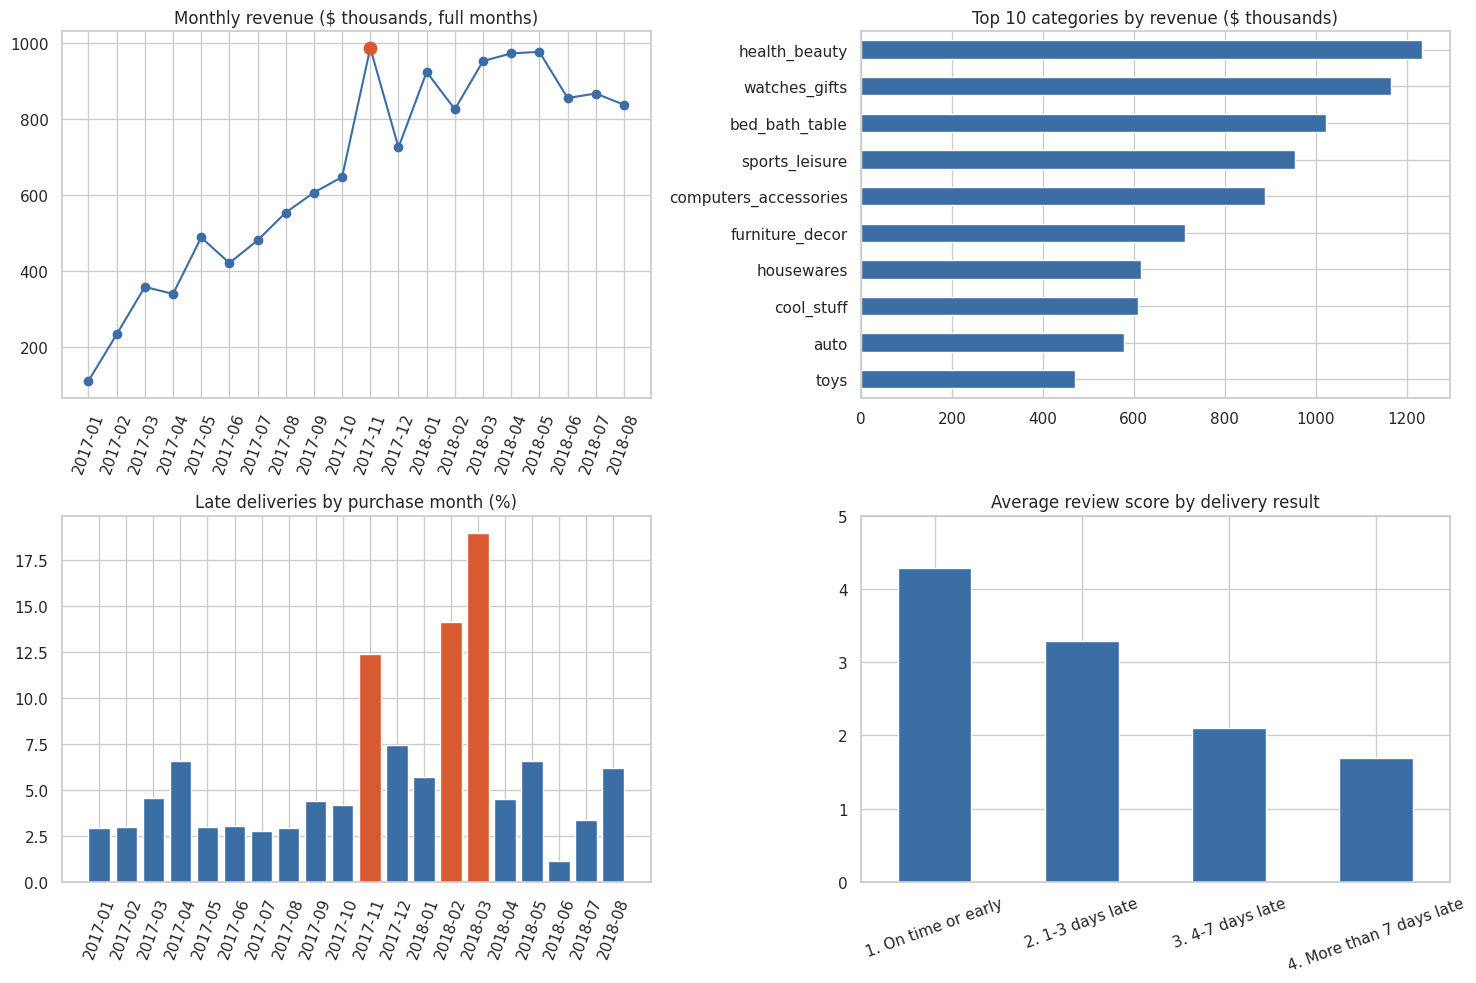

In [21]:
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
mo = pd.read_csv("dashboard/olist_monthly_summary.csv"); mo = mo[mo.is_full_month == 1]
of = pd.read_csv("dashboard/olist_orders_flat.csv"); itf = pd.read_csv("dashboard/olist_items_flat.csv")
fig, ax = plt.subplots(2, 2, figsize=(15, 10))
ax[0, 0].plot(mo["month"], mo["revenue"] / 1000, marker="o", color="#3b6ea5")
peak = mo.loc[mo["revenue"].idxmax()]
ax[0, 0].scatter(peak["month"], peak["revenue"] / 1000, color="#D85A30", zorder=3, s=80)
ax[0, 0].set_title("Monthly revenue ($ thousands, full months)"); ax[0, 0].tick_params(axis="x", rotation=70)
cat = itf.groupby("product_category")["revenue"].sum().sort_values().tail(10) / 1000
cat.plot.barh(ax=ax[0, 1], color="#3b6ea5"); ax[0, 1].set_title("Top 10 categories by revenue ($ thousands)"); ax[0, 1].set_ylabel("")
late = of[(of.purchase_month.between("2017-01", "2018-08")) & of.is_late.notna()].groupby("purchase_month")["is_late"].mean() * 100
ax[1, 0].bar(late.index, late.values, color=["#D85A30" if v > 10 else "#3b6ea5" for v in late.values])
ax[1, 0].set_title("Late deliveries by purchase month (%)"); ax[1, 0].tick_params(axis="x", rotation=70)
rs = of[of.review_score.notna() & (of.delivery_result != "5. Not delivered / no date")].groupby("delivery_result")["review_score"].mean()
rs.plot.bar(ax=ax[1, 1], color="#3b6ea5"); ax[1, 1].set_title("Average review score by delivery result")
ax[1, 1].set_xlabel(""); ax[1, 1].tick_params(axis="x", rotation=20); ax[1, 1].set_ylim(0, 5)
plt.tight_layout(); plt.show()

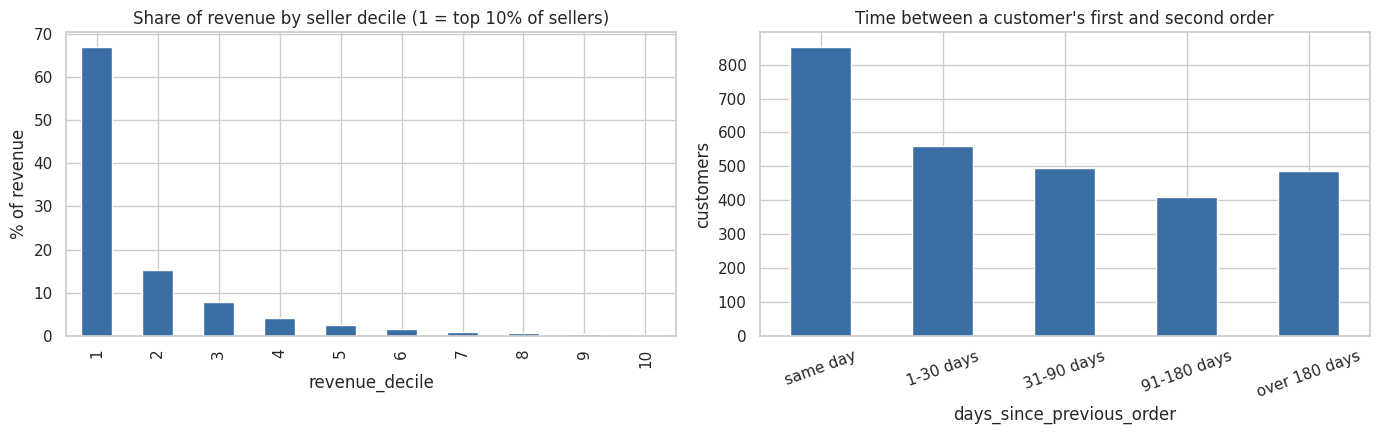

In [22]:
sl = pd.read_csv("dashboard/olist_sellers_summary.csv")
sec = of[of.customer_order_number == 2]["days_since_previous_order"]
bins = pd.cut(sec, [-0.01, 0.99999, 30, 90, 180, 10000], labels=["same day", "1-30 days", "31-90 days", "91-180 days", "over 180 days"])
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
(sl.groupby("revenue_decile")["revenue_share_pct"].sum()).plot.bar(ax=ax[0], color="#3b6ea5")
ax[0].set_title("Share of revenue by seller decile (1 = top 10% of sellers)"); ax[0].set_ylabel("% of revenue")
bins.value_counts().reindex(["same day", "1-30 days", "31-90 days", "91-180 days", "over 180 days"]).plot.bar(ax=ax[1], color="#3b6ea5")
ax[1].set_title("Time between a customer's first and second order"); ax[1].set_ylabel("customers"); ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

## 6. Findings (auto-generated from the data above)

In [23]:
d_items = itf[itf.is_delivered == 1]
rev = d_items.revenue.sum(); n_del = of.is_delivered.sum()
ytd = mo.assign(y=mo.month.str[:4], m=mo.month.str[5:7]).query("m <= '08'").groupby("y")["revenue"].sum()
peak = mo.loc[mo.revenue.idxmax()]
y18 = mo[mo.month.str[:4] == "2018"]
cats = itf.groupby("product_category")["revenue"].sum().sort_values(ascending=False)
st = d_items.groupby("customer_state")["revenue"].sum().sort_values(ascending=False)
cust = of[of.is_delivered == 1].drop_duplicates("customer_unique_id")
rep = of[of.customer_order_number == 2]
dl = of[of.is_late.notna()]
rs = of[of.review_score.notna() & of.days_vs_estimate.notna()]
print(f"1. Revenue ${rev:,.0f} from {n_del:,} delivered orders; average order value ${rev/n_del:,.2f}.")
print(f"2. Jan-Aug 2018 revenue was {(ytd['2018']/ytd['2017']-1)*100:.0f}% above Jan-Aug 2017 (${ytd['2017']/1e6:.2f}M -> ${ytd['2018']/1e6:.2f}M).")
print(f"3. Peak month: {peak['month']} (${peak['revenue']:,.0f}). In 2018, monthly revenue stayed between ${y18.revenue.min():,.0f} and ${y18.revenue.max():,.0f} (growth flattened).")
print(f"4. {cats.index[0]} is the top category ({cats.iloc[0]/cats.sum()*100:.1f}% of revenue); the top 10 categories hold {cats.head(10).sum()/cats.sum()*100:.1f}%. Sao Paulo (SP) buys {st['SP']/st.sum()*100:.1f}% of revenue.")
print(f"5. Only {(cust.customer_type == 'Repeat').sum()/len(cust)*100:.1f}% of customers ordered more than once; repeat customers bring {of[of.customer_type == 'Repeat'].order_revenue.sum()/rev*100:.1f}% of revenue. "
      f"{(rep.days_since_previous_order < 1).mean()*100:.1f}% of second orders came within 24 hours of the first.")
print(f"6. {dl.is_late.mean()*100:.2f}% of deliveries were late; the worst month was {late.idxmax()} ({late.max():.1f}%).")
print(f"7. Average review: {rs[rs.days_vs_estimate <= 0].review_score.mean():.2f} for on-time orders vs {rs[rs.days_vs_estimate > 7].review_score.mean():.2f} for orders more than 7 days late.")
print(f"8. The top 10% of sellers ({(sl.revenue_decile == 1).sum()} of {len(sl):,}) earn {sl[sl.revenue_decile == 1].revenue_share_pct.sum():.1f}% of revenue.")

1. Revenue $13,221,498 from 96,478 delivered orders; average order value $137.04.
2. Jan-Aug 2018 revenue was 141% above Jan-Aug 2017 ($2.99M -> $7.22M).
3. Peak month: 2017-11 ($987,765). In 2018, monthly revenue stayed between $826,437 and $977,545 (growth flattened).
4. health_beauty is the top category (9.3% of revenue); the top 10 categories hold 62.4%. Sao Paulo (SP) buys 38.3% of revenue.
5. Only 3.0% of customers ordered more than once; repeat customers bring 5.5% of revenue. 30.5% of second orders came within 24 hours of the first.
6. 6.77% of deliveries were late; the worst month was 2018-03 (19.0%).
7. Average review: 4.29 for on-time orders vs 1.70 for orders more than 7 days late.
8. The top 10% of sellers (297 of 2,970) earn 67.1% of revenue.


## 7. Recommendations
- Protect delivery in peak periods (November and the early months of the year): late deliveries rise sharply then, and late orders get much worse reviews.
- Build a reason to come back: very few customers reorder, so test follow-up offers 30 to 90 days after a first purchase.
- Review the large share of revenue that depends on a few categories and on Sao Paulo, and test marketing in under-served states.
- Work closely with the top sellers (they carry most of the revenue) and coach the sellers with the most late deliveries.

**Limitations:** public data from 2016-2018; revenue excludes freight and counts delivered orders only; late is measured against the estimate the platform gave, not the customer's expectation; reviews exist for most but not all orders; causes behind delays are not in the data.